# E2 · Fuente geoespacial y linaje de datos
**Observatorio de Ocupación Hotelera de Colima** · Maximiliano Encarnación Velázquez Rodríguez

1. **Fuente especializada geoespacial.** DENUE (INEGI): establecimientos de hospedaje de Colima con
   coordenadas. Marco Geoestadístico (INEGI): límites municipales. Se procesan con GeoPandas.
2. **Linaje.** Cada registro de la capa Oro se rastrea hasta su archivo y fila en Bronce, con su fecha de
   ingesta y su huella SHA-256.

La ética y legalidad de todas las fuentes se documenta en [`docs/etica-datos.md`](../etica-datos.md).

In [1]:
import json, sys, warnings
from pathlib import Path
RAIZ = Path.cwd().resolve().parents[1] if Path.cwd().name == "E2" else Path.cwd()
sys.path.insert(0, str(RAIZ)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from src.pipeline import config as C, bronce, geo, linaje, ejecutar
IMG = RAIZ / "docs" / "E2" / "img"; IMG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
ejecutar.main()
leer = lambda n: json.load(open(RAIZ / "reports" / "E2" / n, encoding="utf-8"))

etapa       fuente                  entrada  válidos cuarent.
1_entrada   datatur                   31147    31141        6
1_entrada   banxico_tipo_cambio        2985     2985        0
1_entrada   banxico_inpc                142      142        0
2_plata     datatur                   31288    31287        1
3_oro       oro_destino_mes            6900     6898        2
G1_entrada  inegi_denue_colima          294      294        0
G2_plata    inegi_denue_colima          294      294        0

Plata: 31287 registros · Oro: 6898 destino-mes · Cuarentena: 9


## 1. Fuentes nuevas en Bronce
| Fuente | Recurso | Formato | Acceso | Licencia |
|---|---|---|---|---|
| DENUE Colima (INEGI) | `inegi.org.mx/contenidos/masiva/denue/denue_06_csv.zip` | ZIP → CSV latin-1 (42 mil establecimientos) | descarga masiva pública | Términos de Libre Uso del INEGI |
| Marco Geoestadístico (INEGI) | `gaia.inegi.org.mx/wscatgeo/v2/geo/mgem/06` | GeoJSON (10 municipios + Censo 2020) | servicio web público | Términos de Libre Uso del INEGI |

Se capturan con el mismo extractor ético de E0 (robots.txt, User-Agent identificable, SHA-256, bitácora).
**Se descartó OpenStreetMap/Overpass** porque `overpass-api.de/robots.txt` prohíbe `/api/` para clientes
automatizados.

In [2]:
bit = pd.read_csv(C.BITACORA_BRONCE)
bit[bit.fuente.str.startswith("inegi")][["fecha_utc","fuente","robots","http","estado","bytes","archivo"]]

,fecha_utc,fuente,robots,http,estado,bytes,archivo
13,2026-11-23T02:23:28Z,inegi_denue_colima,robots.txt permite la ruta,200.0,nuevo,3788726,data/bronze/inegi_denue_colima/denue_06_csv_20...
14,2026-11-23T02:23:29Z,inegi_mg_municipios,robots.txt HTTP 404 (no disponible => permitid...,200.0,nuevo,517085,data/bronze/inegi_mg_municipios/mgem_06_colima...


## 2. Minimización de datos y Puerta de Calidad geoespacial
DENUE publica nombre del establecimiento, razón social, teléfono, correo, página web y domicilio. En negocios
pequeños (pensiones, casas de huéspedes) esos campos pueden identificar a una **persona física**. El análisis no
los necesita, así que **se descartan al leer Bronce** y nunca llegan a Plata ni a Oro (principio de minimización).

In [3]:
g = leer("geoespacial.json")
print("Columnas descartadas por privacidad:", g["columnas_descartadas_por_privacidad"])
pd.DataFrame(g["puertas"])[["etapa","fuente","esquema","registros_entrada","registros_validos","registros_cuarentena"]]

Columnas descartadas por privacidad: ['nom_estab', 'raz_social', 'telefono', 'correoelec', 'www', 'tipo_vial', 'nom_vial', 'numero_ext', 'numero_int', 'letra_ext', 'letra_int', 'edificio', 'edificio_e', 'nomb_asent', 'manzana']


,etapa,fuente,esquema,registros_entrada,registros_validos,registros_cuarentena
0,G1_entrada,inegi_denue_colima,denue_hospedaje,294,294,0
1,G2_plata,inegi_denue_colima,denue_hospedaje_plata,294,294,0


Reglas: SCIAN dentro de alojamiento (721xxx), estrato de personal válido, entidad 06, municipio 001–010,
coordenadas dentro de Colima, `fecha_alta` AAAA-MM e id único (**G1**). Tras la unión espacial, el punto debe
caer a menos de 1 km de Colima (**G2**; tolera la generalización de la línea de costa). Además se marca
`municipio_coincide`: si el municipio declarado en DENUE es distinto del municipio donde cae el punto.

In [4]:
print("Establecimientos cuyo municipio declarado no coincide con su ubicación:", g["municipio_no_coincide"])
pd.DataFrame(g["ejemplos_no_coincide"])

Establecimientos cuyo municipio declarado no coincide con su ubicación: 1


,id,municipio,municipio_espacial,distancia_colima_m
0,6256490,Villa de Álvarez,Colima,0.0


## 3. Mapa de la oferta de hospedaje en Colima

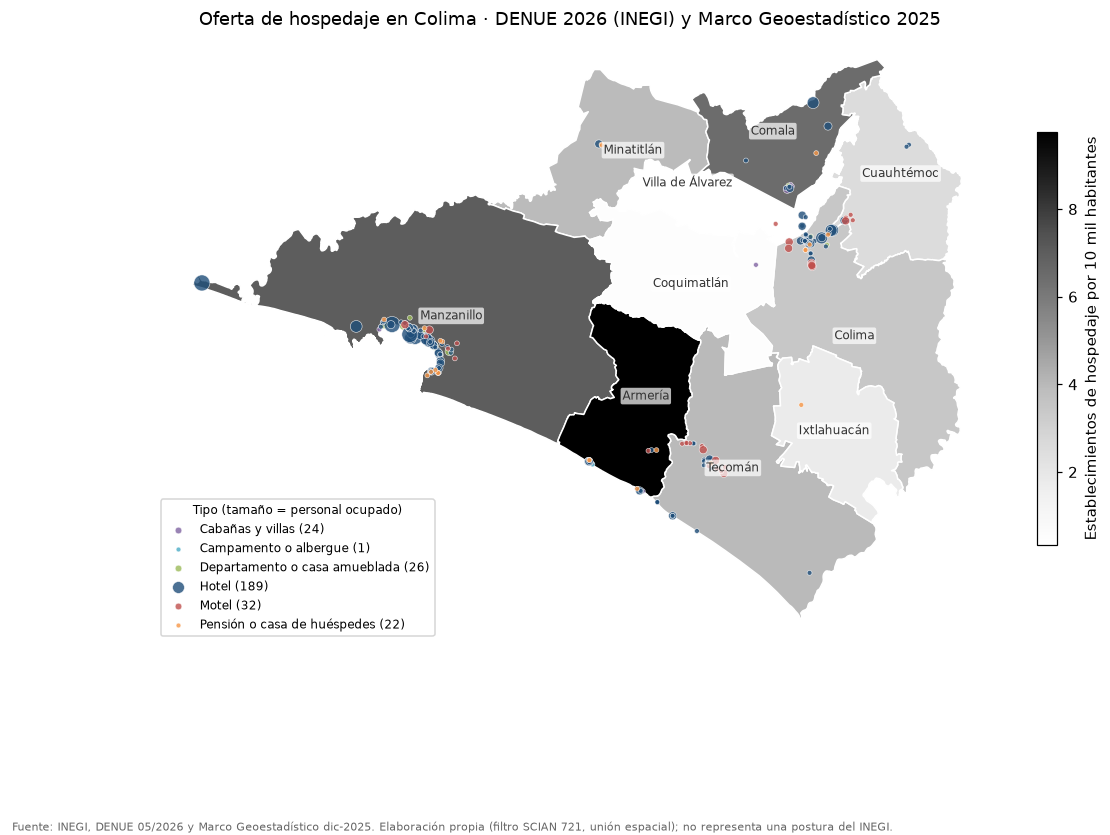

In [5]:
mun = gpd.read_file(C.PLATA / "municipios_colima.geojson")
tab = pd.read_csv(C.ORO / "municipio_hospedaje.csv", dtype={"cvegeo": str})
mun = mun.merge(tab[["cvegeo","establecimientos","establecimientos_por_10k_hab","pct_oferta_estatal"]], on="cvegeo")
est = pd.read_csv(C.ORO / "establecimientos_hospedaje.csv")
pts = gpd.GeoDataFrame(est, geometry=gpd.points_from_xy(est.longitud, est.latitud), crs=4326)

colores = {"Hotel": "#1f4e79", "Motel": "#c0504d", "Departamento o casa amueblada": "#9bbb59",
           "Cabañas y villas": "#8064a2", "Pensión o casa de huéspedes": "#f79646", "Campamento o albergue": "#4bacc6"}
tam = {"Micro": 10, "Pequeño": 28, "Mediano": 60, "Grande": 110}

fig, ax = plt.subplots(figsize=(11, 8))
mun.plot(column="establecimientos_por_10k_hab", cmap="Greys", ax=ax, edgecolor="white", linewidth=1,
         legend=True, legend_kwds={"label": "Establecimientos de hospedaje por 10 mil habitantes", "shrink": .55})
for tipo, sub in pts.groupby("tipo_alojamiento"):
    sub.plot(ax=ax, color=colores[tipo], markersize=sub.tamano.map(tam).to_numpy(), alpha=.8, edgecolor="white",
             linewidth=.4, label=f"{tipo} ({len(sub)})")
for _, r in mun.iterrows():
    p = r.geometry.representative_point()
    if p.x > -104.8:
        ax.annotate(r.nomgeo, (p.x, p.y), ha="center", fontsize=8, color="#333",
                    bbox=dict(boxstyle="round,pad=.15", fc="white", ec="none", alpha=.7))
ax.set_xlim(-104.75, -103.45); ax.set_ylim(18.65, 19.55); ax.set_axis_off()
ax.legend(title="Tipo (tamaño = personal ocupado)", loc="lower left", fontsize=8, title_fontsize=8, frameon=True)
ax.set_title("Oferta de hospedaje en Colima · DENUE 2026 (INEGI) y Marco Geoestadístico 2025", fontsize=12)
ax.annotate("Fuente: INEGI, DENUE 05/2026 y Marco Geoestadístico dic-2025. Elaboración propia (filtro SCIAN 721, unión espacial); no representa una postura del INEGI.",
            (0.01, 0.005), xycoords="figure fraction", fontsize=7, color="#666")
plt.tight_layout(); plt.savefig(IMG / "mapa_hospedaje_colima.png", dpi=150); plt.show()

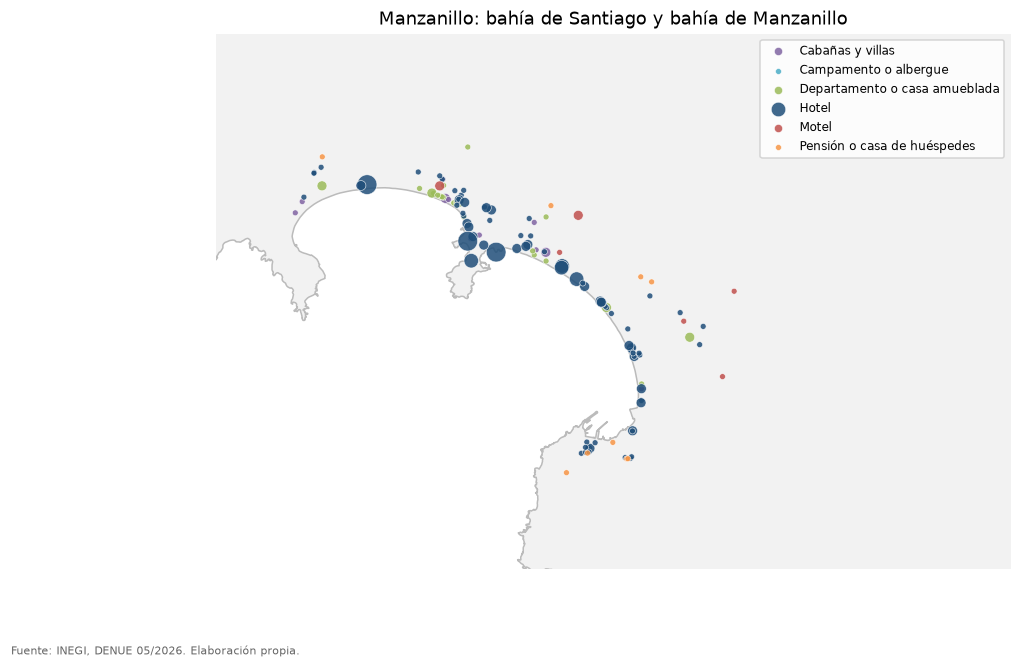

In [6]:
# Acercamiento a la zona hotelera de Manzanillo
fig, ax = plt.subplots(figsize=(10, 6))
mun.plot(ax=ax, color="#f2f2f2", edgecolor="#bbb")
for tipo, sub in pts.groupby("tipo_alojamiento"):
    sub.plot(ax=ax, color=colores[tipo], markersize=sub.tamano.map(tam).to_numpy() * 1.5, alpha=.85, edgecolor="white",
             linewidth=.4, label=tipo)
ax.set_xlim(-104.42, -104.20); ax.set_ylim(19.02, 19.16); ax.set_axis_off()
ax.legend(fontsize=8, loc="upper right"); ax.set_title("Manzanillo: bahía de Santiago y bahía de Manzanillo")
ax.annotate("Fuente: INEGI, DENUE 05/2026. Elaboración propia.", (0.01, 0.01), xycoords="figure fraction", fontsize=7, color="#666")
plt.tight_layout(); plt.savefig(IMG / "mapa_manzanillo.png", dpi=150); plt.show()

In [7]:
# Mapa interactivo (abre docs/E2/mapa_hospedaje_colima.html en el navegador)
m = mun.explore(column="establecimientos_por_10k_hab", cmap="Greys", tiles="CartoDB positron",
                tooltip=["nomgeo","establecimientos","establecimientos_por_10k_hab","pct_oferta_estatal"],
                legend_kwds={"caption": "Establecimientos por 10 mil hab."}, style_kwds={"fillOpacity": .45})
pts.explore(m=m, column="tipo_alojamiento", cmap=list(colores.values()), marker_kwds={"radius": 5},
            tooltip=["tipo_alojamiento","tamano","per_ocu","municipio_espacial","anio_alta","id_oro"])
m.save(str(RAIZ / "docs" / "E2" / "mapa_hospedaje_colima.html")); print("Mapa interactivo guardado")

Mapa interactivo guardado


In [8]:
cols = ["nomgeo","establecimientos","pct_oferta_estatal","establecimientos_por_10k_hab","establecimientos_por_100km2",
        "personal_estimado","pct_micro","n_Hotel","cuartos_datatur_2024","cuartos_por_establecimiento"]
tab[cols]

,nomgeo,establecimientos,pct_oferta_estatal,establecimientos_por_10k_hab,establecimientos_por_100km2,personal_estimado,pct_micro,n_Hotel,cuartos_datatur_2024,cuartos_por_establecimiento
0,Manzanillo,134,45.6,7.01,9.72,2844,69.4,85,4313.0,32.2
1,Colima,54,18.4,3.44,7.28,716,68.5,40,1164.0,21.6
2,Tecomán,46,15.6,3.96,4.98,369,82.6,31,NaN,NaN
3,Armería,27,9.2,9.77,6.47,174,85.2,17,NaN,NaN
4,Comala,14,4.8,6.46,4.48,265,71.4,6,NaN,NaN
5,Cuauhtémoc,8,2.7,2.56,1.95,63,75.0,4,NaN,NaN
6,Villa de Álvarez,5,1.7,0.33,1.75,74,60.0,4,NaN,NaN
7,Minatitlán,4,1.4,3.91,0.97,29,75.0,2,NaN,NaN
8,Ixtlahuacán,1,0.3,1.78,0.27,3,100.0,0,NaN,NaN
9,Coquimatlán,1,0.3,0.48,0.20,3,100.0,0,NaN,NaN


**Lectura.**
* **Manzanillo concentra el 46 % de los establecimientos de hospedaje del estado** y el 63 % del empleo estimado
  del sector. Colima capital tiene el 18 % de los establecimientos.
* **Armería** tiene la mayor densidad por habitante (9.8 por cada 10 mil), por su franja de playa (Cuyutlán, El
  Paraíso). **Villa de Álvarez** casi no tiene hospedaje aunque es el segundo municipio más poblado: sus visitantes
  se alojan en Colima capital, que forma la misma zona urbana.
* **73 % de los establecimientos son micro (0–10 personas)**; sólo 4 tienen 251 o más empleados, y están en
  Manzanillo.
* Al cruzar con DataTur, los hoteles de Manzanillo tienen en promedio **≈ 32 cuartos por establecimiento**, contra
  ≈ 22 en Colima capital: el puerto concentra hoteles más grandes. *(DataTur cubre hoteles de categoría turística
  y DENUE todo el alojamiento, así que la razón es una aproximación.)*

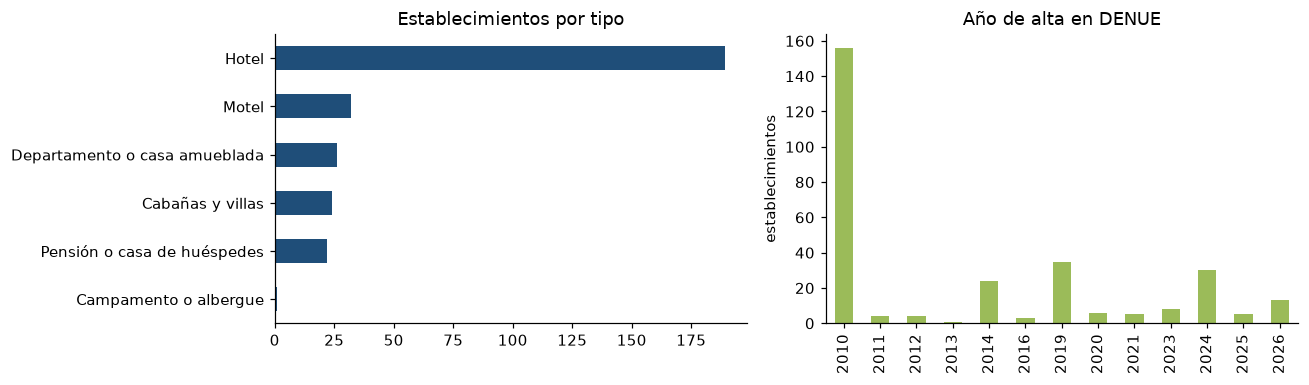

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
est.groupby(["tipo_alojamiento"]).size().sort_values().plot.barh(ax=ax[0], color="#1f4e79")
ax[0].set(title="Establecimientos por tipo", xlabel="", ylabel="")
(est.anio_alta.value_counts().sort_index()).plot.bar(ax=ax[1], color="#9bbb59")
ax[1].set(title="Año de alta en DENUE", xlabel="", ylabel="establecimientos")
plt.tight_layout(); plt.savefig(IMG / "denue_tipo_alta.png"); plt.show()

El pico de 2010 en el año de alta corresponde al levantamiento censal que dio origen al DENUE, no a una ola de
aperturas. Por eso `fecha_alta` no se interpreta como fecha de apertura del negocio (sesgo de registro).

## 4. Linaje: de cualquier registro de Oro a su origen en Bronce
Cada registro lleva desde Bronce las columnas `id_bronce`, `archivo_origen`, `fila_origen`, `sha256_bronce` y
`fecha_ingesta`. Al agregar o integrar, el pipeline escribe la tabla larga `data/gold/linaje_oro.csv`: una fila por
cada par (registro de Oro, registro crudo que lo produjo), con el **rol** de la transformación.

In [10]:
v = leer("linaje.json")
print(f"Registros de linaje: {v['registros_linaje']:,} · registros de Oro: {v['ids_oro']:,} · "
      f"archivos Bronce: {v['archivos_bronce']} · sin linaje: {v['registros_oro_sin_linaje']} · íntegro: {v['integro']}")
pd.Series(v["por_tabla"]).rename("registros de Oro rastreables").to_frame()

Registros de linaje: 34,505 · registros de Oro: 7,310 · archivos Bronce: 5 · sin linaje: 0 · íntegro: True


,registros de Oro rastreables
destino_mes,6898
establecimientos_hospedaje,294
indicadores_mes,108
municipio_hospedaje,10


In [11]:
lin = pd.read_csv(linaje.ARCHIVO_LINAJE, dtype=str)
lin.groupby(["tabla_oro","fuente","rol"]).size().rename("filas").to_frame()

filas
tabla_oro                  fuente              rol                                                    
destino_mes                datatur             agregación centro×categoría→centro                31135
                                               base de imputación (hueco interno)                  292
establecimientos_hospedaje inegi_denue_colima  registro DENUE (columnas personales descartadas)    294
indicadores_mes            banxico_inpc        INPC 12 meses antes (variación anual)               108
                                               INPC del mes                                        108
                           banxico_tipo_cambio promedio mensual del FIX diario                    2264
municipio_hospedaje        inegi_denue_colima  conteo por unión espacial punto→municipio           294
                           inegi_mg_municipios polígono, área y población (Censo 2020)              10

### 4.1 Ejemplo: ¿de dónde sale la ocupación de Manzanillo en julio de 2024?

In [12]:
oro = pd.read_csv(C.ORO / "destino_mes.csv")
oro[oro.id_oro == "Manzanillo|2024-07"][["id_oro","ocupacion_pct","tipo_cambio","inflacion_anual_pct",
     "categorias_reportadas","registros_imputados","fecha_ingesta_datatur","linaje_tipo_cambio","linaje_inpc"]].T

,3006
id_oro,Manzanillo|2024-07
ocupacion_pct,61.352
tipo_cambio,18.1117
inflacion_anual_pct,5.566
categorias_reportadas,4
registros_imputados,0
fecha_ingesta_datatur,2026-11-10T21:42:00Z
linaje_tipo_cambio,data/bronze/banxico_tipo_cambio_fix/SF43718_ti...
linaje_inpc,banxico_inpc:eb4543f07a:102|banxico_inpc:eb454...


In [13]:
r = linaje.rastrear("Manzanillo|2024-07", limite=4)
pd.concat([r[["fuente","rol","archivo_origen","fila_origen","fecha_ingesta"]].reset_index(drop=True),
           pd.json_normalize(r["registro_crudo"].tolist())], axis=1).head(10)

,fuente,rol,archivo_origen,fila_origen,fecha_ingesta,anio,mes,tipo_centro,subtipo_centro,centro,categoria,cuartos_disponibles,cuartos_ocupados_no_residentes,cuartos_ocupados_residentes,llegada_turistas_no_residentes,llegada_turistas_residentes,turistas_noche_no_residentes,turistas_noche_residentes,fecha,dato
0,datatur,agregación centro×categoría→centro,data/bronze/datatur/Base70centros_2026-11-10_m...,29567,2026-11-10T21:42:00Z,2024,07,Centros de Playa,Tradicionales,Manzanillo,2 estrellas,8308,0,5931,0,12736,0,12736,NaN,NaN
1,datatur,agregación centro×categoría→centro,data/bronze/datatur/Base70centros_2026-11-10_m...,29568,2026-11-10T21:42:00Z,2024,07,Centros de Playa,Tradicionales,Manzanillo,3 estrellas,67208,2529,32002,1485,51909,3383,95855,NaN,NaN
2,datatur,agregación centro×categoría→centro,data/bronze/datatur/Base70centros_2026-11-10_m...,29569,2026-11-10T21:42:00Z,2024,07,Centros de Playa,Tradicionales,Manzanillo,4 estrellas,18290,310,15829,167,13963,358,31258,NaN,NaN
3,datatur,agregación centro×categoría→centro,data/bronze/datatur/Base70centros_2026-11-10_m...,29570,2026-11-10T21:42:00Z,2024,07,Centros de Playa,Tradicionales,Manzanillo,5 estrellas,39618,1946,23311,1795,20190,4658,60820,NaN,NaN
4,banxico_tipo_cambio,promedio mensual del FIX diario,data/bronze/banxico_tipo_cambio_fix/SF43718_ti...,2388,2026-11-14T17:03:44Z,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01/07/2024,18.3897
5,banxico_tipo_cambio,promedio mensual del FIX diario,data/bronze/banxico_tipo_cambio_fix/SF43718_ti...,2389,2026-11-14T17:03:44Z,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,02/07/2024,18.2485
6,banxico_tipo_cambio,promedio mensual del FIX diario,data/bronze/banxico_tipo_cambio_fix/SF43718_ti...,2390,2026-11-14T17:03:44Z,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,03/07/2024,18.1355
7,banxico_tipo_cambio,promedio mensual del FIX diario,data/bronze/banxico_tipo_cambio_fix/SF43718_ti...,2391,2026-11-14T17:03:44Z,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,04/07/2024,18.0958
8,banxico_inpc,INPC del mes,data/bronze/banxico_inpc/SP1_inpc_2026-11-14T1...,114,2026-11-14T17:03:45Z,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01/07/2024,136.003000000000
9,banxico_inpc,INPC 12 meses antes (variación anual),data/bronze/banxico_inpc/SP1_inpc_2026-11-14T1...,102,2026-11-14T17:03:45Z,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01/07/2023,128.832000000000


Cada fila apunta al **archivo crudo exacto** y a la **fila** de donde salió el dato, con la **fecha de ingesta**. La
ocupación de julio 2024 suma 4 categorías hoteleras de DataTur (1★ no existe en Manzanillo: hueco estructural) y
usa los 23 días hábiles del FIX de ese mes y dos valores del INPC.

### 4.2 Ejemplo: un registro imputado y un municipio

In [14]:
imp = lin[lin.rol.str.startswith("base de imputación")]
print("Registros de Oro que dependen de imputación:", imp.id_oro.nunique())
ej = imp.id_oro.iloc[0]
linaje.rastrear(ej, limite=2)[["id_oro","fuente","rol","id_bronce","fila_origen","fecha_ingesta"]]

Registros de Oro que dependen de imputación: 133


,id_oro,fuente,rol,id_bronce,fila_origen,fecha_ingesta
99,Acapulco|2019-02,datatur,agregación centro×categoría→centro,datatur:a8ca3f9bf3:10958,10958,2026-11-10T21:42:00Z
207,Acapulco|2019-02,datatur,agregación centro×categoría→centro,datatur:a8ca3f9bf3:10959,10959,2026-11-10T21:42:00Z
31135,Acapulco|2019-02,datatur,base de imputación (hueco interno),datatur:a8ca3f9bf3:10663,10663,2026-11-10T21:42:00Z
31136,Acapulco|2019-02,datatur,base de imputación (hueco interno),datatur:a8ca3f9bf3:11252,11252,2026-11-10T21:42:00Z
32203,banxico|2019-02,banxico_tipo_cambio,promedio mensual del FIX diario,banxico_tipo_cambio_fix:49f5db5624:1027,1027,2026-11-14T17:03:44Z
32204,banxico|2019-02,banxico_tipo_cambio,promedio mensual del FIX diario,banxico_tipo_cambio_fix:49f5db5624:1028,1028,2026-11-14T17:03:44Z
33728,banxico|2019-02,banxico_inpc,INPC del mes,banxico_inpc:eb4543f07a:49,49,2026-11-14T17:03:45Z
33836,banxico|2019-02,banxico_inpc,INPC 12 meses antes (variación anual),banxico_inpc:eb4543f07a:37,37,2026-11-14T17:03:45Z


In [15]:
r = linaje.rastrear("municipio|06007", limite=3)
r[["id_oro","fuente","rol","id_bronce","fecha_ingesta"]]

,id_oro,fuente,rol,id_bronce,fecha_ingesta
34201,municipio|06007,inegi_denue_colima,conteo por unión espacial punto→municipio,inegi_denue_colima:948e292e56:26809,2026-11-23T02:23:28Z
34202,municipio|06007,inegi_denue_colima,conteo por unión espacial punto→municipio,inegi_denue_colima:948e292e56:27123,2026-11-23T02:23:28Z
34204,municipio|06007,inegi_denue_colima,conteo por unión espacial punto→municipio,inegi_denue_colima:948e292e56:27246,2026-11-23T02:23:28Z
34500,municipio|06007,inegi_mg_municipios,"polígono, área y población (Censo 2020)",inegi_mg_municipios:a345fd583e:5,2026-11-23T02:23:29Z


### 4.3 Verificación automática
`linaje.verificar()` corre en cada ejecución del pipeline. Comprueba que cada archivo citado exista, que su
SHA-256 coincida con la bitácora de captura y que las filas estén dentro de rango. Si un registro de Oro no tiene
linaje, el pipeline **se detiene** y GitHub Actions marca la corrida en rojo.

In [16]:
print(linaje.verificar())

{'registros_linaje': 34505, 'ids_oro': 7310, 'archivos_bronce': 5, 'problemas': [], 'integro': True}
